In [38]:
import pandas as pd

df = pd.read_csv("train_data.csv")

In [39]:
col=df.columns
print(len(col))

156


In [40]:
AI=[]
add_col=['WorkExp','NewRole','LearnCodeAI','LearnCode']
curr_col=[]
first_21AI=[]
for c in col:
  if c.startswith("AI"):
    AI.append(c)


print(len(AI))

first_21AI=AI[:21]
curr_col.extend(first_21AI)
curr_col.extend(add_col)
curr_col.append('JobSat')

print(len(curr_col))
print(curr_col)


42
26
['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIModelsHaveEntry', 'AIModelsWantEntry', 'AISelect', 'AISent', 'AIAcc', 'AIComplex', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents', 'AIAgentChange', 'WorkExp', 'NewRole', 'LearnCodeAI', 'LearnCode', 'JobSat']


In [41]:
df = df[curr_col]
df = df.dropna(subset = ['JobSat'])
print(df.shape)

(23961, 26)


In [42]:
print(df.shape)
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print(df.shape)

(23961, 26)
4
(23957, 26)


In [43]:
print(df.shape)
df=df.dropna(how='all')
print(df.shape)

(23957, 26)
(23957, 26)


In [44]:
df.describe()

,WorkExp,JobSat
count,23358.000000,23957.000000
mean,13.497945,7.203364
std,10.051465,1.995227
min,1.000000,0.000000
25%,5.000000,6.000000
50%,11.000000,8.000000
75%,20.000000,8.000000
max,100.000000,10.000000


In [45]:
print(df.dtypes)

AILearnHow                                   object
AIThreat                                     object
AIModelsChoice                               object
AIModelsHaveWorkedWith                       object
AIModelsWantToWorkWith                       object
AIModelsAdmired                              object
AIModelsHaveEntry                            object
AIModelsWantEntry                            object
AISelect                                     object
AISent                                       object
AIAcc                                        object
AIComplex                                    object
AIToolCurrently partially AI                 object
AIToolDon't plan to use AI for this task     object
AIToolPlan to partially use AI               object
AIToolPlan to mostly use AI                  object
AIToolCurrently mostly AI                    object
AIFrustration                                object
AIExplain                                    object
AIAgents    

In [46]:
print(len(df.columns))
print(df.columns)
drop_col=df.columns[df.isnull().mean() >= 0.7]
print(drop_col)
df= df.drop(columns=drop_col)
print(len(df.columns))
print(df.columns)

26
Index(['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith',
       'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIModelsHaveEntry',
       'AIModelsWantEntry', 'AISelect', 'AISent', 'AIAcc', 'AIComplex',
       'AIToolCurrently partially AI',
       'AIToolDon't plan to use AI for this task',
       'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI',
       'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'AIAgents',
       'AIAgentChange', 'WorkExp', 'NewRole', 'LearnCodeAI', 'LearnCode',
       'JobSat'],
      dtype='object')
Index(['AIModelsHaveEntry', 'AIModelsWantEntry'], dtype='object')
24
Index(['AILearnHow', 'AIThreat', 'AIModelsChoice', 'AIModelsHaveWorkedWith',
       'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AISelect', 'AISent',
       'AIAcc', 'AIComplex', 'AIToolCurrently partially AI',
       'AIToolDon't plan to use AI for this task',
       'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI',
       'AIToolCur

In [47]:
for c in df.columns:
    print( df[c].value_counts() )
 

AILearnHow
AI CodeGen tools or AI-enabled apps                                                                                                                                                                                                                                                                                                                                                                                                                                        1416
Other online resources (e.g. standard search, forum, online community)                                                                                                                                                                                                                                                                                                                                                                                                      501
Colleague or on-the-job training                             

In [48]:
for c in df.columns:
    print(c,df[c].isnull().sum())

AILearnHow 7995
AIThreat 126
AIModelsChoice 3609
AIModelsHaveWorkedWith 12594
AIModelsWantToWorkWith 15693
AIModelsAdmired 16060
AISelect 1576
AISent 1725
AIAcc 1806
AIComplex 1818
AIToolCurrently partially AI 9597
AIToolDon't plan to use AI for this task 6730
AIToolPlan to partially use AI 8553
AIToolPlan to mostly use AI 15354
AIToolCurrently mostly AI 16493
AIFrustration 2928
AIExplain 5927
AIAgents 2630
AIAgentChange 2769
WorkExp 599
NewRole 326
LearnCodeAI 49
LearnCode 6691
JobSat 0


Numeric Features 

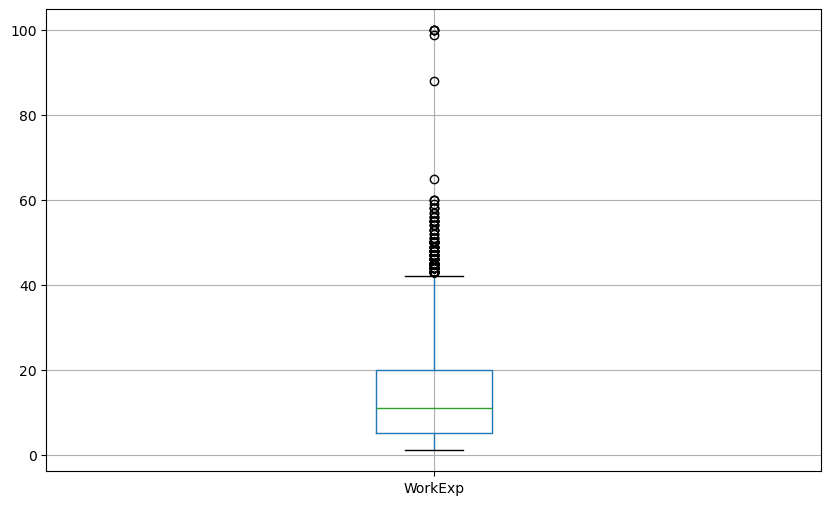

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
df.boxplot(column='WorkExp')
plt.show()

Data is skewed ---->  Fill with median

In [50]:
df['WorkExp'].fillna(df['WorkExp'].median(), inplace=True)


C:\Users\homel\AppData\Local\Temp\ipykernel_12156\3028425614.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['WorkExp'].fillna(df['WorkExp'].median(), inplace=True)


In [51]:
print(len(df[df['WorkExp']>45]))

113


In [52]:
df=df[df['WorkExp']<=45]
print(df.shape)
df['WorkExp'].corr(df['JobSat'])


(23844, 24)


np.float64(0.09911624211007927)

Categorical Features

In [53]:
target_col = 'JobSat'

cat_cols = df.select_dtypes(include=['object']).columns

print(df[cat_cols].nunique())

AILearnHow                                  1184
AIThreat                                       3
AIModelsChoice                                 2
AIModelsHaveWorkedWith                      1770
AIModelsWantToWorkWith                      1507
AIModelsAdmired                             1113
AISelect                                       5
AISent                                         6
AIAcc                                          5
AIComplex                                      6
AIToolCurrently partially AI                2990
AIToolDon't plan to use AI for this task    2841
AIToolPlan to partially use AI              3668
AIToolPlan to mostly use AI                 1682
AIToolCurrently mostly AI                   1225
AIFrustration                                 96
AIExplain                                   7659
AIAgents                                       6
AIAgentChange                                  5
NewRole                                        5
LearnCodeAI         

In [54]:
mul_choice=['AILearnHow', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'LearnCode']


In [55]:
for c in df.columns:
    if c not in mul_choice and c not in ['JobSat', 'WorkExp']:
       df[c].fillna(df[c].mode()[0], inplace=True)

C:\Users\homel\AppData\Local\Temp\ipykernel_12156\1252158448.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[c].fillna(df[c].mode()[0], inplace=True)


In [56]:
multi_cols = []

for col in df.columns:
    if df[col].astype(str).str.contains(';').any():
        multi_cols.append(col)

print(multi_cols)

['AILearnHow', 'AIModelsHaveWorkedWith', 'AIModelsWantToWorkWith', 'AIModelsAdmired', 'AIToolCurrently partially AI', "AIToolDon't plan to use AI for this task", 'AIToolPlan to partially use AI', 'AIToolPlan to mostly use AI', 'AIToolCurrently mostly AI', 'AIFrustration', 'AIExplain', 'LearnCode']


In [57]:
for c in df[mul_choice]:
    print(df[c].str.split(';').explode().value_counts())



AILearnHow
AI CodeGen tools or AI-enabled apps                                       8632
Other online resources (e.g. standard search, forum, online community)    7183
Technical documentation (is generated for/by the tool or system)          7101
Videos (not associated with specific online course or certification)      6271
Blogs or podcasts                                                         4858
Colleague or on-the-job training                                          3747
Stack Overflow or Stack Exchange                                          2616
Online Courses or Certification (includes all media types)                2427
Books / Physical media                                                    1219
School (i.e., University, College, etc)                                    668
Other (please specify):                                                    649
Games or coding challenges                                                 406
Coding Bootcamp                          

In [58]:
from sklearn.preprocessing import MultiLabelBinarizer

# Step 1 — parse all multi-choice columns first (outside the loop)
for c in mul_choice:
    df[c] = df[c].fillna("").apply(
        lambda x: [i.strip() for i in x.split(";") if i.strip()]
    )

all_encoded = []

for c in mul_choice:
    mlb = MultiLabelBinarizer()
    encoded = mlb.fit_transform(df[c])         
    encoded_df = pd.DataFrame(
        encoded,
        columns=[f"{c}__{cls}" for cls in mlb.classes_],  
        index=df.index
    )
    all_encoded.append(encoded_df)

df = df.drop(columns=mul_choice)
df = pd.concat([df] + all_encoded, axis=1)

In [59]:
df.shape

(23844, 167)

In [60]:
df.isnull().sum()

AIThreat                                                                             0
AIModelsChoice                                                                       0
AISelect                                                                             0
AISent                                                                               0
AIAcc                                                                                0
                                                                                    ..
LearnCode__Other online resources (e.g. standard search, forum, online community)    0
LearnCode__School (i.e., University, College, etc)                                   0
LearnCode__Stack Overflow or Stack Exchange                                          0
LearnCode__Technical documentation (is generated for/by the tool or system)          0
LearnCode__Videos (not associated with specific online course or certification)      0
Length: 167, dtype: int64

In [61]:
df['AIExplain'] = df['AIExplain'].astype(str).str.lower().apply(
    lambda x: "yes" if "yes" in x
    else "no" if "no" in x
    else "other"
)

In [62]:
df

,AIThreat,AIModelsChoice,AISelect,AISent,AIAcc,AIComplex,AIExplain,AIAgents,AIAgentChange,WorkExp,...,LearnCode__Coding Bootcamp,LearnCode__Colleague or on-the-job training,LearnCode__Games or coding challenges,LearnCode__Online Courses or Certification (includes all media types),LearnCode__Other (please specify):,"LearnCode__Other online resources (e.g. standard search, forum, online community)","LearnCode__School (i.e., University, College, etc)",LearnCode__Stack Overflow or Stack Exchange,LearnCode__Technical documentation (is generated for/by the tool or system),LearnCode__Videos (not associated with specific online course or certification)
0,I'm not sure,Yes,"Yes, I use AI tools monthly or infrequently",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,no,"Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,8.0,...,0,0,0,1,0,1,0,0,0,0
1,I'm not sure,Yes,"Yes, I use AI tools weekly",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,no,"No, and I don't plan to",Not at all or minimally,2.0,...,0,0,0,1,0,1,0,1,0,1
2,No,Yes,"Yes, I use AI tools daily",Favorable,Somewhat trust,Neither good or bad at handling complex tasks,no,"Yes, I use AI agents at work weekly","Yes, somewhat",10.0,...,0,0,0,1,0,0,0,0,1,1
3,No,No,"Yes, I use AI tools weekly",Favorable,Somewhat trust,Bad at handling complex tasks,no,"Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,4.0,...,0,0,0,0,0,1,0,1,1,1
4,I'm not sure,No,"Yes, I use AI tools daily",Indifferent,Somewhat distrust,"Good, but not great at handling complex tasks",no,"Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,15.0,...,0,1,0,1,0,1,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44176,No,Yes,"Yes, I use AI tools daily",Favorable,Somewhat trust,"Good, but not great at handling complex tasks",no,"No, and I don't plan to","Yes, somewhat",5.0,...,0,0,0,1,0,0,0,1,1,0
44178,No,Yes,"Yes, I use AI tools weekly",Indifferent,Neither trust nor distrust,Bad at handling complex tasks,no,"No, but I plan to","Yes, somewhat",20.0,...,0,0,0,0,0,0,0,0,0,0
44179,Yes,No,"Yes, I use AI tools weekly",Unfavorable,Somewhat distrust,Very poor at handling complex tasks,no,"No, and I don't plan to",Not at all or minimally,5.0,...,0,0,0,0,0,1,0,1,1,1
44180,No,No,"No, and I don't plan to",Unfavorable,Highly distrust,I don't use AI tools for complex tasks / I don...,no,"No, and I don't plan to",Not at all or minimally,1.0,...,0,1,0,0,0,1,0,0,0,0


In [63]:
cat_cols = df.select_dtypes(include=['object']).columns
num_cols= df.select_dtypes(include=['number']).columns
print(cat_cols,len(cat_cols))
print(num_cols,len(num_cols))

Index(['AIThreat', 'AIModelsChoice', 'AISelect', 'AISent', 'AIAcc',
       'AIComplex', 'AIExplain', 'AIAgents', 'AIAgentChange', 'NewRole',
       'LearnCodeAI'],
      dtype='object') 11
Index(['WorkExp', 'JobSat', 'AILearnHow__AI CodeGen tools or AI-enabled apps',
       'AILearnHow__Blogs or podcasts', 'AILearnHow__Books / Physical media',
       'AILearnHow__Coding Bootcamp',
       'AILearnHow__Colleague or on-the-job training',
       'AILearnHow__Games or coding challenges',
       'AILearnHow__Online Courses or Certification (includes all media types)',
       'AILearnHow__Other (please specify):',
       ...
       'LearnCode__Coding Bootcamp',
       'LearnCode__Colleague or on-the-job training',
       'LearnCode__Games or coding challenges',
       'LearnCode__Online Courses or Certification (includes all media types)',
       'LearnCode__Other (please specify):',
       'LearnCode__Other online resources (e.g. standard search, forum, online community)',
       'LearnCode_

WorkExp                                                                               0.099116
AIFrustration__I’ve become less confident in my own problem-solving                   0.069229
AILearnHow__Technical documentation (is generated for/by the tool or system)          0.054193
AILearnHow__Colleague or on-the-job training                                          0.041994
AIFrustration__It’s hard to understand how or why the code works                      0.039935
LearnCode__Colleague or on-the-job training                                           0.037564
AILearnHow__Stack Overflow or Stack Exchange                                          0.033852
AIModelsAdmired__Gemini (Pro Reasoning models)                                        0.032727
AIToolCurrently partially AI__Testing code                                            0.032412
AILearnHow__Other online resources (e.g. standard search, forum, online community)    0.028333
dtype: float64


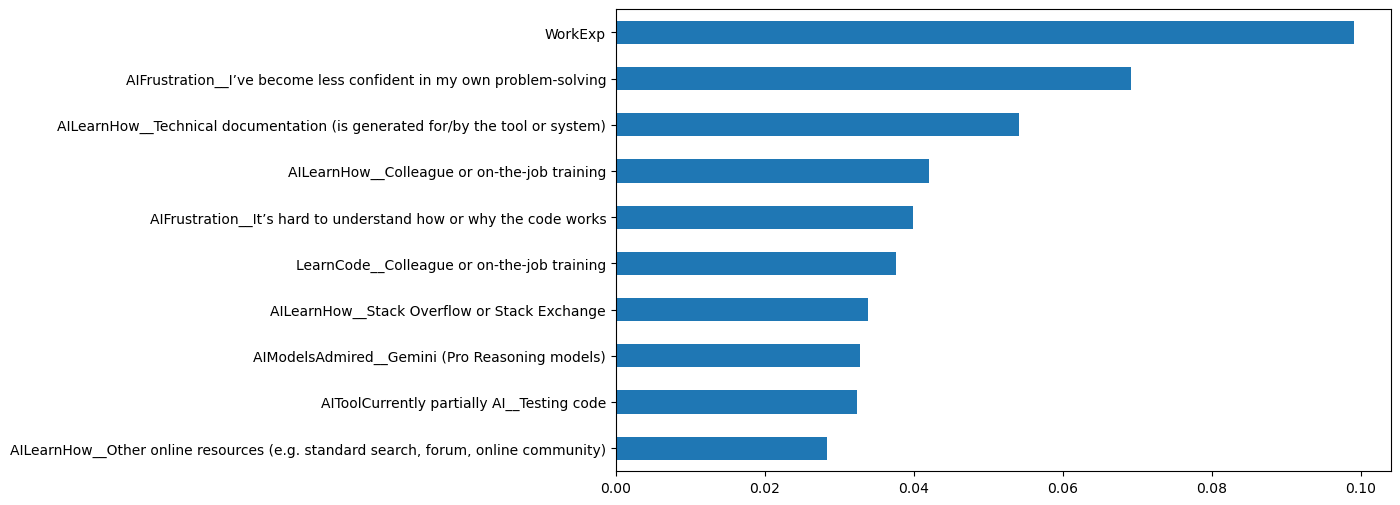

In [64]:
corr = df[num_cols].corrwith(df[target_col])
corr=corr.drop(target_col)
top10 = corr.abs().sort_values(ascending=False).head(10)

print(top10)
plt.figure(figsize=(10,6))
top10.sort_values().plot(kind='barh')
plt.show()

In [65]:
top_cols=top10.index.tolist()
df = df[top_cols + [target_col] + cat_cols.tolist()]
print(len(df.columns))
df.columns

22


Index(['WorkExp',
       'AIFrustration__I’ve become less confident in my own problem-solving',
       'AILearnHow__Technical documentation (is generated for/by the tool or system)',
       'AILearnHow__Colleague or on-the-job training',
       'AIFrustration__It’s hard to understand how or why the code works',
       'LearnCode__Colleague or on-the-job training',
       'AILearnHow__Stack Overflow or Stack Exchange',
       'AIModelsAdmired__Gemini (Pro Reasoning models)',
       'AIToolCurrently partially AI__Testing code',
       'AILearnHow__Other online resources (e.g. standard search, forum, online community)',
       'JobSat', 'AIThreat', 'AIModelsChoice', 'AISelect', 'AISent', 'AIAcc',
       'AIComplex', 'AIExplain', 'AIAgents', 'AIAgentChange', 'NewRole',
       'LearnCodeAI'],
      dtype='object')

In [66]:
from sklearn.feature_selection import f_regression


cat_encoded = pd.get_dummies(df[cat_cols], drop_first=True)

f_vals, p_vals = f_regression(cat_encoded, df[target_col])

anova_df = pd.DataFrame({
    "feature": cat_encoded.columns,
    "F_score": f_vals,
    "p_value": p_vals
})

 
top_cat = anova_df[anova_df["p_value"] < 0.05] \
            .sort_values("F_score", ascending=False) \
            .head(10)
top_cat_cols = top_cat["feature"].tolist()
cat_encoded=cat_encoded.astype(int)
print(top_cat)


                                              feature      F_score  \
33  NewRole_I have strongly considered changing my...  1946.151805   
0                                         AIThreat_No   480.322700   
32  NewRole_I have somewhat considered changing my...   418.108963   
1                                        AIThreat_Yes   374.615846   
35  NewRole_I have transitioned into a new career ...   124.027560   
10                              AISent_Very favorable   104.205566   
20      AIComplex_Very well at handling complex tasks    59.981551   
39  LearnCodeAI_Yes, I learned how to use AI-enabl...    56.337165   
11                            AISent_Very unfavorable    48.631305   
25        AIAgents_Yes, I use AI agents at work daily    41.893493   

          p_value  
33   0.000000e+00  
0   1.997910e-105  
32   3.888000e-92  
1    7.999090e-83  
35   9.782206e-29  
10   2.047483e-24  
20   9.954970e-15  
39   6.318711e-14  
11   3.169643e-12  
25   9.825626e-11  


In [67]:
final_df = pd.concat([
    df[top_cols],                 # top numeric
    cat_encoded[top_cat_cols],        # top categorical
    df[[target_col]]                  # target
], axis=1)

In [68]:
final_df.shape

(23844, 21)

In [69]:
final_df

,WorkExp,AIFrustration__I’ve become less confident in my own problem-solving,AILearnHow__Technical documentation (is generated for/by the tool or system),AILearnHow__Colleague or on-the-job training,AIFrustration__It’s hard to understand how or why the code works,LearnCode__Colleague or on-the-job training,AILearnHow__Stack Overflow or Stack Exchange,AIModelsAdmired__Gemini (Pro Reasoning models),AIToolCurrently partially AI__Testing code,"AILearnHow__Other online resources (e.g. standard search, forum, online community)",...,AIThreat_No,NewRole_I have somewhat considered changing my career and/or the industry I work in,AIThreat_Yes,NewRole_I have transitioned into a new career and/or industry voluntarily,AISent_Very favorable,AIComplex_Very well at handling complex tasks,"LearnCodeAI_Yes, I learned how to use AI-enabled tools required for my job or to benefit my career",AISent_Very unfavorable,"AIAgents_Yes, I use AI agents at work daily",JobSat
0,8.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.0
1,2.0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,9.0
2,10.0,0,1,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,8.0
3,4.0,0,0,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,0,6.0
4,15.0,0,1,1,0,1,0,0,0,1,...,0,1,0,0,0,0,1,0,0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44176,5.0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,9.0
44178,20.0,0,0,0,0,0,0,0,0,0,...,1,1,0,0,0,0,0,0,0,8.0
44179,5.0,1,0,0,1,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,7.0
44180,1.0,0,0,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,9.0
